# ACA N.º 2 · Aprendizaje Automático (CUN)
## Pasos 3 y 4. Modelado con redes neuronales, evaluación y métricas
**Proyecto:** Predicción de deserción estudiantil con redes neuronales
**Pilar:** Educación · **Dataset:** UCI *Predict Students Dropout and Academic Success* (Martins et al., 2021)
**Docente:** Dr. Hamilton Rivera Flor

**Integrantes:** Johan Manuel Buitrago Segura · Yadlif Mateo Hernández Zapata · Cristian David Muñoz Sánchez · Edna Catalina Osorio Alzate · Camilo José Patiño Rodríguez

---
### ¿Qué hace este notebook?
Recibe los datos preparados en el **Paso 2** (121 entradas, tres conjuntos y dos estrategias contra el desbalance) y:

**Paso 3 · Modelado**
1. Entrena dos **modelos de referencia** clásicos para saber qué resultado debe igualar o superar la red.
2. Define un **perceptrón multicapa (MLP) profundo** y compara tres formas de tratar el desbalance.
3. Ajusta el tamaño de la red (búsqueda pequeña de arquitectura).
4. Entrena una **red recurrente (GRU)** que lee los dos semestres como una secuencia, y la compara con el MLP.
5. Elige el modelo final **solo con el conjunto de validación**.

**Paso 4 · Evaluación**
6. Muestra las **curvas de aprendizaje** (pérdida y exactitud en entrenamiento y validación).
7. Evalúa el modelo final **una sola vez** en el conjunto de prueba: *loss*, *accuracy*, F1, matriz de confusión y AUC.
8. Analiza los errores y el uso práctico (detectar abandono).
9. Guarda el modelo y las métricas para la app de Streamlit y el póster.

> **Regla que se mantiene del Paso 2:** el conjunto de **prueba** no interviene en ninguna decisión. Todo se elige con validación; la prueba solo se usa al final para reportar.

## 1. Configuración

In [1]:
import os, warnings
warnings.filterwarnings("ignore")
try:                                    # Keras 3 funciona igual sobre JAX, TensorFlow o PyTorch.
    import jax                          # Se usa JAX por ser el más liviano (útil para desplegar la app).
    os.environ["KERAS_BACKEND"] = "jax"
except ImportError:
    os.environ["KERAS_BACKEND"] = "tensorflow"

import json, zipfile, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import keras, sklearn
from keras import layers, regularizers
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (f1_score, accuracy_score, log_loss, classification_report,
                             confusion_matrix, roc_auc_score, precision_score, recall_score)

SEMILLA = 42
SEMILLAS = [42, 7, 21, 99, 123]         # cada configuración se entrena 5 veces (ver sección 4)
AZUL, NEGRO, GRIS = "#1d4ed8", "#0b1220", "#9aa6bf"
print("Keras", keras.__version__, "| backend:", keras.backend.backend(), "| scikit-learn", sklearn.__version__)

Keras 3.15.1 | backend: jax | scikit-learn 1.9.1


## 2. Carga de los datos preparados en el Paso 2
El notebook busca la carpeta `artefactos_paso2/` o el archivo `artefactos_paso2.zip` en la carpeta actual. En Colab, si no están, pide subir el `.zip`.

In [2]:
CARPETA = "artefactos_paso2"
if not os.path.isdir(CARPETA):
    if not os.path.exists(CARPETA + ".zip"):
        from google.colab import files
        print("Sube el archivo artefactos_paso2.zip generado en el Paso 2:")
        files.upload()
    zipfile.ZipFile(CARPETA + ".zip").extractall(CARPETA)

d = np.load(f"{CARPETA}/datos_preparados.npz")
with open(f"{CARPETA}/config_preparacion.json", encoding="utf-8") as f:
    cfg = json.load(f)

Xtr, ytr = d["X_train"], d["y_train"]
Xtr_smote, ytr_smote = d["X_train_smote"], d["y_train_smote"]
Xva, yva = d["X_val"], d["y_val"]
Xte, yte = d["X_test"], d["y_test"]

CLASES = cfg["clases"]
NOMBRES = [cfg["nombres_clases"][c] for c in CLASES]          # Abandono, Sigue matriculado, Se gradúa
PESOS_CLASE = {int(k): v for k, v in cfg["pesos_clase"].items()}
N_ENTRADAS = Xtr.shape[1]

print(f"Entrenamiento: {Xtr.shape} | con SMOTE-NC: {Xtr_smote.shape} | Validación: {Xva.shape} | Prueba: {Xte.shape}")
print("Clases:", dict(enumerate(NOMBRES)))

Entrenamiento: (3096, 121) | con SMOTE-NC: (4635, 121) | Validación: (664, 121) | Prueba: (664, 121)
Clases: {0: 'Abandono', 1: 'Sigue matriculado', 2: 'Se gradúa'}


## 3. Modelos de referencia (línea base)
Antes de entrenar una red conviene saber **qué tan difícil es el problema**. Se entrenan dos modelos clásicos con exactamente los mismos datos:

| Referencia | Para qué sirve |
|---|---|
| **Regresión logística** | Es el «piso»: un modelo lineal. Si la red no lo supera, sus capas ocultas no están aportando nada. |
| **Gradient Boosting** (mismos hiperparámetros del mejor modelo de la ACA 1) | Es el «techo» razonable: los modelos de árboles suelen ser los más fuertes en datos tabulares (Grinsztajn et al., 2022). |

La métrica principal es el **F1 macro**: promedia el F1 de las tres clases dándoles el mismo peso, así la clase pequeña («sigue matriculado») cuenta igual que las demás.

In [3]:
def metricas(y_real, proba):
    # Métricas a partir de las probabilidades predichas (una columna por clase).
    pred = proba.argmax(axis=1)
    f1c = f1_score(y_real, pred, average=None)
    return {"loss": log_loss(y_real, proba, labels=[0, 1, 2]),
            "accuracy": accuracy_score(y_real, pred),
            "f1_macro": f1_score(y_real, pred, average="macro"),
            "f1_abandono": f1c[0], "f1_matriculado": f1c[1], "f1_gradua": f1c[2]}

referencias = {
    "Regresión logística": LogisticRegression(max_iter=3000, class_weight="balanced"),
    "Gradient Boosting (ACA 1)": HistGradientBoostingClassifier(
        learning_rate=0.1, max_depth=3, max_leaf_nodes=15, l2_regularization=1.0,
        class_weight="balanced", random_state=SEMILLA),
}
ref_val = {}
for nombre, m in referencias.items():
    m.fit(Xtr, ytr)
    ref_val[nombre] = metricas(yva, m.predict_proba(Xva))
pd.DataFrame(ref_val).T.round(3)

,loss,accuracy,f1_macro,f1_abandono,f1_matriculado,f1_gradua
Regresión logística,0.610,0.735,0.696,0.772,0.495,0.822
Gradient Boosting (ACA 1),0.581,0.759,0.723,0.798,0.537,0.835


**Interpretación.** Estas dos cifras son la vara de medir de todo el notebook (validación, F1 macro):
- **Regresión logística: 0,696.** Un modelo lineal ya resuelve buena parte del problema. Una red que quede por debajo no justifica su complejidad.
- **Gradient Boosting: 0,723.** Es el mejor tipo de modelo de la ACA 1, reentrenado aquí con la misma partición para que la comparación sea justa.

En ambos casos la clase «sigue matriculado» es la difícil (F1 entre 0,50 y 0,54), mientras que «se gradúa» supera 0,82. Esto no es un defecto del modelo sino del problema: un estudiante que sigue matriculado se parece a veces a quien va a abandonar y a veces a quien va a graduarse.

**Expectativa realista:** la distancia entre el piso y el techo es de menos de 3 puntos. La red neuronal no va a producir un salto grande; el objetivo razonable es quedar en ese rango.

## 4. Paso 3 · Arquitectura de la red: perceptrón multicapa (MLP)
### ¿Por qué un MLP?
- Los datos son **tabulares**: cada estudiante es una fila de 121 números. No hay imágenes (donde una CNN aprovecha la cercanía entre píxeles) ni texto (donde un Transformer aprovecha el orden de las palabras).
- El enunciado propone para deserción académica «redes recurrentes (LSTM/GRU) o **perceptrones multicapa (MLP) profundos**». La alternativa recurrente también se entrena y se compara en la sección 6.

### ¿Cómo está construido?
```
121 entradas → [Densa → BatchNorm → ReLU → Dropout] × N capas ocultas → Densa(3) + softmax
```
| Pieza | Qué hace | Por qué se usa |
|---|---|---|
| **Capa densa** | Cada neurona combina todas las entradas con pesos que se aprenden | Permite aprender combinaciones entre variables (p. ej. deuda **y** bajo rendimiento) |
| **ReLU** | Deja pasar los valores positivos y anula los negativos | Sin una función no lineal, varias capas equivaldrían a una sola regresión logística |
| **Batch Normalization** | Reescala las salidas de cada capa | Entrenamiento más estable y rápido (Ioffe y Szegedy, 2015) |
| **Dropout** | Apaga neuronas al azar durante el entrenamiento | Evita que la red memorice: solo hay 3.096 estudiantes (Srivastava et al., 2014) |
| **Regularización L2** | Penaliza pesos muy grandes | Segundo freno contra el sobreajuste |
| **Softmax (3 neuronas)** | Convierte la salida en 3 probabilidades que suman 1 | Una por clase: abandono, sigue matriculado, se gradúa |

**Entrenamiento:** optimizador Adam (Kingma y Ba, 2015), pérdida *entropía cruzada categórica*, lotes de 64 estudiantes y hasta 200 épocas, con dos controles automáticos:
- **Early stopping:** si la pérdida de validación no mejora en 15 épocas, se detiene y se recuperan los mejores pesos.
- **Reducción de la tasa de aprendizaje:** si la validación se estanca 6 épocas, la tasa se reduce a la mitad para afinar.

In [4]:
class F1MacroValidacion(keras.callbacks.Callback):
    """Calcula el F1 macro de validación al final de cada época y lo guarda en el historial."""
    def __init__(self, X, y):
        super().__init__(); self.X, self.y = X, y
    def on_epoch_end(self, epoch, logs=None):
        pred = self.model.predict(self.X, verbose=0, batch_size=1024).argmax(axis=1)
        logs["val_f1_macro"] = f1_score(self.y, pred, average="macro")


def crear_mlp(capas=(128, 64, 32), dropout=0.3, l2=1e-4, tasa_aprendizaje=1e-3):
    entrada = keras.Input(shape=(N_ENTRADAS,), name="estudiante")
    x = entrada
    for i, neuronas in enumerate(capas, start=1):
        x = layers.Dense(neuronas, kernel_regularizer=regularizers.l2(l2), name=f"densa_{i}")(x)
        x = layers.BatchNormalization(name=f"norm_{i}")(x)
        x = layers.Activation("relu", name=f"relu_{i}")(x)
        x = layers.Dropout(dropout, name=f"dropout_{i}")(x)
    salida = layers.Dense(3, activation="softmax", name="probabilidades")(x)
    modelo = keras.Model(entrada, salida, name="mlp_desercion")
    modelo.compile(optimizer=keras.optimizers.Adam(tasa_aprendizaje),
                   loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return modelo


def entrenar(constructor, X, y, X_val, y_val, pesos=None, semilla=SEMILLA, epocas=200):
    """Crea y entrena un modelo. Devuelve el modelo (con sus mejores pesos) y el historial por época."""
    keras.utils.set_random_seed(semilla)            # fija el azar: pesos iniciales, dropout y orden de los lotes
    modelo = constructor()
    historial = modelo.fit(
        X, y, validation_data=(X_val, y_val), epochs=epocas, batch_size=64, class_weight=pesos, verbose=0,
        callbacks=[F1MacroValidacion(X_val, y_val),
                   keras.callbacks.EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True),
                   keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=6, min_lr=1e-5)])
    return modelo, historial.history


def repetir(constructor, X, y, X_val, y_val, pesos=None, semillas=SEMILLAS):
    """Entrena la misma configuración con varias semillas y devuelve las métricas de validación de cada una."""
    filas = []
    for s in semillas:
        modelo, h = entrenar(constructor, X, y, X_val, y_val, pesos, semilla=s)
        fila = metricas(y_val, modelo.predict(X_val, verbose=0, batch_size=1024))
        fila["epocas"] = len(h["loss"])
        filas.append(fila)
    return pd.DataFrame(filas)


crear_mlp().summary()

Model: "mlp_desercion"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ estudiante (InputLayer)         │ (None, 121)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densa_1 (Dense)                 │ (None, 128)            │        15,616 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ norm_1 (BatchNormalization)     │ (None, 128)            │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_1 (Activation)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densa_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ norm_2 (BatchNormalization)     │ (None, 64)             │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_2 (Activation)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densa_3 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ norm_3 (BatchNormalization)     │ (None, 32)             │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_3 (Activation)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ probabilidades (Dense)          │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 26,947 (105.26 KB)

 Trainable params: 26,499 (103.51 KB)

 Non-trainable params: 448 (1.75 KB)

### ¿Por qué entrenar cada configuración 5 veces?
Una red neuronal empieza con pesos al azar, así que dos entrenamientos idénticos dan resultados algo distintos. Con 664 estudiantes en validación, esa variación puede ser de 1 a 2 puntos de F1. Si se comparara una sola corrida de cada opción, se podría elegir un «ganador» por pura suerte. Por eso cada configuración se entrena con **5 semillas** y se compara el **promedio** (± desviación estándar).

### 4.1 Experimento 1: ¿cómo tratar el desbalance de clases?
Se comparan las dos estrategias preparadas en el Paso 2 más un control sin compensación:

In [5]:
estrategias = {
    "Sin compensar (control)": (Xtr, ytr, None),
    "A. Pesos por clase":      (Xtr, ytr, PESOS_CLASE),
    "B. SMOTE-NC":             (Xtr_smote, ytr_smote, None),
}
exp1 = {nombre: repetir(crear_mlp, X, y, Xva, yva, pesos) for nombre, (X, y, pesos) in estrategias.items()}

def resumen(experimento):
    # Promedio ± desviación estándar de las corridas de cada configuración.
    cols = ["f1_macro", "accuracy", "f1_abandono", "f1_matriculado", "f1_gradua", "loss", "epocas"]
    tabla = pd.DataFrame({k: v[cols].mean() for k, v in experimento.items()}).T
    tabla.insert(1, "± f1_macro", [v["f1_macro"].std() for v in experimento.values()])
    return tabla.round(3)

res1 = resumen(exp1)
res1

,f1_macro,± f1_macro,accuracy,f1_abandono,f1_matriculado,f1_gradua,loss,epocas
Sin compensar (control),0.699,0.009,0.772,0.795,0.444,0.859,0.551,30.2
A. Pesos por clase,0.704,0.008,0.747,0.770,0.503,0.839,0.589,26.6
B. SMOTE-NC,0.702,0.004,0.753,0.766,0.491,0.848,0.584,26.0


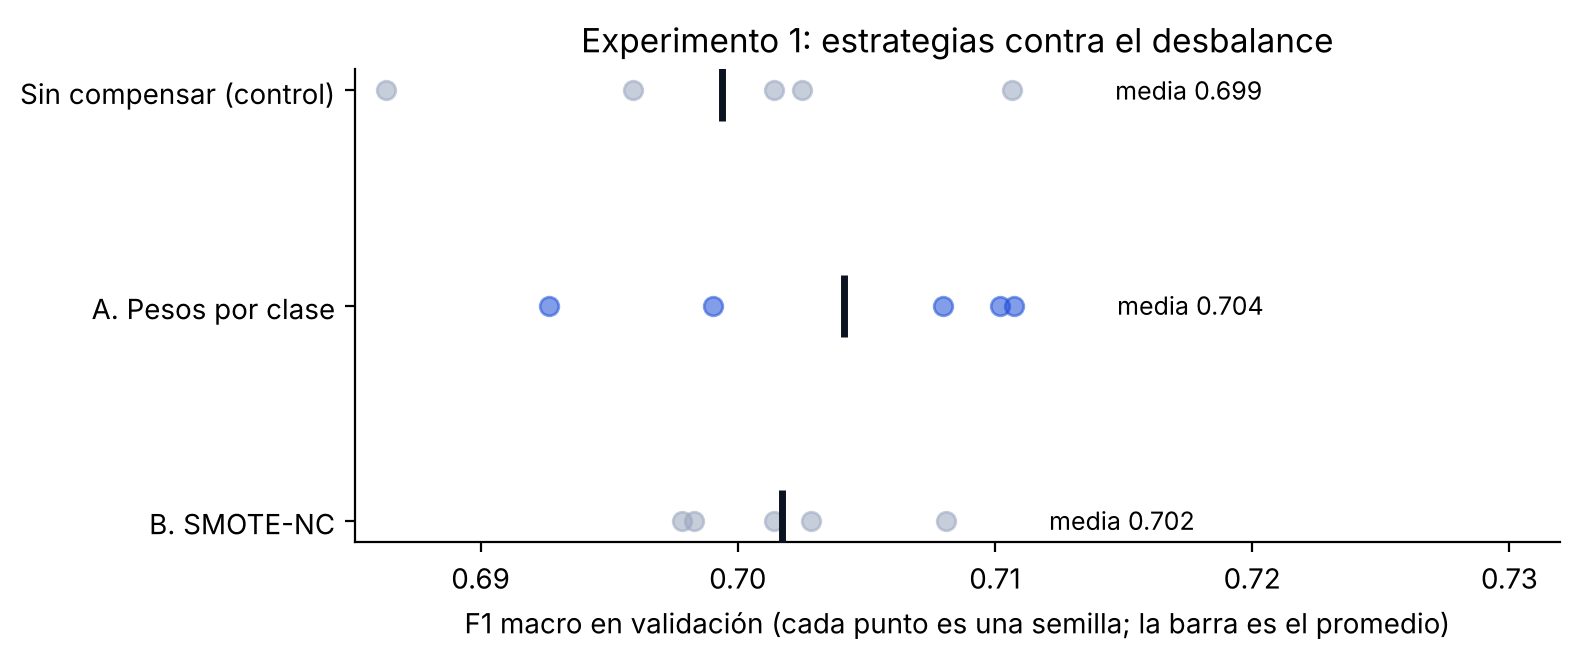

Estrategia elegida (mayor F1 macro promedio en validación): A. Pesos por clase


In [6]:
fig, ax = plt.subplots(figsize=(8, 3.4))
mejor1 = res1["f1_macro"].idxmax()
for i, (nombre, df_e) in enumerate(exp1.items()):
    color = AZUL if nombre == mejor1 else GRIS
    ax.scatter(df_e["f1_macro"], [i] * len(df_e), color=color, alpha=.55, s=45, zorder=2)
    ax.scatter(df_e["f1_macro"].mean(), i, color=NEGRO, marker="|", s=500, lw=2.5, zorder=3)
    ax.text(df_e["f1_macro"].max() + 0.004, i, f"media {df_e['f1_macro'].mean():.3f}", va="center", fontsize=9)
ax.set_yticks(range(len(exp1)), list(exp1)); ax.invert_yaxis()
ax.set_xlabel("F1 macro en validación (cada punto es una semilla; la barra es el promedio)")
ax.set_title("Experimento 1: estrategias contra el desbalance")
ax.set_xlim(ax.get_xlim()[0], ax.get_xlim()[1] + 0.02)
ax.spines[["top", "right"]].set_visible(False); plt.tight_layout(); plt.show()
print("Estrategia elegida (mayor F1 macro promedio en validación):", mejor1)

**Interpretación.** Las tres opciones quedan muy cerca en F1 macro (0,699, 0,704 y 0,702), con diferencias **menores que la variación entre semillas** (± 0,004 a 0,009). Es decir, ninguna estrategia es claramente superior en la métrica global. Lo que sí cambia es **cómo se reparte** el acierto:
- **Sin compensar**, la red obtiene la mayor exactitud (0,772) pero el peor F1 en «sigue matriculado» (0,444): acierta más en total porque favorece a las clases grandes. Es el efecto que se anticipó en el Paso 1.
- **Con pesos por clase**, el F1 de «sigue matriculado» sube a 0,503 a cambio de unos 2,5 puntos de exactitud.
- **SMOTE-NC** queda en un punto intermedio (0,491) y no supera a los pesos, a pesar de entrenar con 1.539 estudiantes sintéticos.

Se elige **pesos por clase**: tiene el mayor promedio, mejora la clase minoritaria y es más simple (no agrega datos artificiales ni alarga el entrenamiento). La conclusión honesta es que el aumento de datos con SMOTE-NC **no aportó** una mejora medible en este problema.

### 4.2 Experimento 2: ¿de qué tamaño debe ser la red?
Con la estrategia elegida se prueban cuatro tamaños. Una red más grande puede aprender patrones más complejos, pero con pocos datos también memoriza con más facilidad; por eso el *dropout* sube junto con el tamaño.

In [7]:
X_ent, y_ent, pesos_ent = estrategias[mejor1]

arquitecturas = {
    "Pequeña · 64-32":           dict(capas=(64, 32), dropout=0.2),
    "Mediana · 128-64-32":       dict(capas=(128, 64, 32), dropout=0.3),
    "Grande · 256-128-64":       dict(capas=(256, 128, 64), dropout=0.4),
    "Profunda · 256-128-64-32":  dict(capas=(256, 128, 64, 32), dropout=0.4),
}
exp2 = {}
for nombre, params in arquitecturas.items():
    if nombre.startswith("Mediana"):
        exp2[nombre] = exp1[mejor1]                      # es la misma configuración del experimento 1
    else:
        exp2[nombre] = repetir(lambda p=params: crear_mlp(**p), X_ent, y_ent, Xva, yva, pesos_ent)

res2 = resumen(exp2)
res2.insert(0, "parámetros", [crear_mlp(**p).count_params() for p in arquitecturas.values()])
mejor2 = res2["f1_macro"].idxmax()
print("Arquitectura elegida:", mejor2)
res2

Arquitectura elegida: Grande · 256-128-64


,parámetros,f1_macro,± f1_macro,accuracy,f1_abandono,f1_matriculado,f1_gradua,loss,epocas
Pequeña · 64-32,10371,0.700,0.010,0.748,0.767,0.493,0.841,0.587,27.4
Mediana · 128-64-32,26947,0.704,0.008,0.747,0.770,0.503,0.839,0.589,26.6
Grande · 256-128-64,74371,0.709,0.013,0.754,0.781,0.499,0.845,0.569,26.8
Profunda · 256-128-64-32,76483,0.708,0.011,0.748,0.769,0.510,0.846,0.580,29.6


**Interpretación.** Multiplicar por siete el número de parámetros (de 10.371 a 74.371) mueve el F1 macro de 0,700 a 0,709, menos de un punto y dentro del margen de variación entre semillas (± 0,010 a 0,013). Agregar una cuarta capa oculta tampoco ayuda (0,708).

Esto indica que el límite **no está en la capacidad de la red sino en la información disponible**: con 3.096 estudiantes y estas variables, una red más grande no encuentra patrones nuevos. Se toma la arquitectura **256-128-64** por tener el mayor promedio, sabiendo que la ventaja sobre las demás no es concluyente.

## 5. Entrenamiento del MLP elegido
Se entrena la configuración ganadora con la semilla del proyecto (42) y se conserva su historial por época para las curvas de aprendizaje del Paso 4.

In [8]:
PARAMS_MLP = arquitecturas[mejor2]
mlp, hist_mlp = entrenar(lambda: crear_mlp(**PARAMS_MLP), X_ent, y_ent, Xva, yva, pesos_ent, semilla=SEMILLA)
val_mlp = metricas(yva, mlp.predict(Xva, verbose=0))
print(f"Épocas entrenadas: {len(hist_mlp['loss'])} | mejor época: {int(np.argmin(hist_mlp['val_loss'])) + 1}")
print({k: round(float(v), 3) for k, v in val_mlp.items()})

Épocas entrenadas: 28 | mejor época: 13
{'loss': 0.564, 'accuracy': 0.755, 'f1_macro': 0.71, 'f1_abandono': 0.791, 'f1_matriculado': 0.498, 'f1_gradua': 0.841}


## 6. Alternativa recurrente: red GRU sobre los dos semestres
El enunciado también propone redes recurrentes para la «predicción temporal de deserción». Una red recurrente lee una **secuencia** paso a paso y guarda una memoria de lo que ya vio. Aquí la secuencia es la trayectoria académica:

```
paso 1 = 1.er semestre → [convalidadas, inscritas, evaluadas, aprobadas, promedio, sin evaluar]
paso 2 = 2.º semestre  → [convalidadas, inscritas, evaluadas, aprobadas, promedio, sin evaluar]
```
Se usa una **GRU** (*Gated Recurrent Unit*; Cho et al., 2014), que es una versión más liviana de la LSTM y suele bastar en secuencias cortas. El modelo es **híbrido**, con dos ramas:
- **Rama temporal:** la GRU lee los dos semestres (secuencia de 2 pasos × 6 variables).
- **Rama estática:** una capa densa recibe lo que no cambia en el tiempo (datos demográficos, financieros, carrera, contexto económico).

Las dos ramas se unen y pasan a la capa de salida *softmax*.

**Comparación justa:** a la GRU **no** se le entregan las 4 variables creadas a mano en el Paso 2 (tasas de aprobación y cambios entre semestres). La pregunta es precisamente si la red recurrente puede aprender sola esa tendencia a partir de la secuencia.

In [9]:
columnas = cfg["columnas_red"]
METRICAS_SEM = ["credited", "enrolled", "evaluations", "approved", "grade", "without_evaluations"]
idx_seq = [[columnas.index(f"num__curricular_units_{sem}_sem_{m}") for m in METRICAS_SEM] for sem in ("1st", "2nd")]
CREADAS = ["num__tasa_aprob_1er_sem", "num__tasa_aprob_2do_sem", "num__cambio_aprobadas", "num__cambio_promedio"]
usadas = {i for paso in idx_seq for i in paso} | {columnas.index(c) for c in CREADAS}
idx_est = [i for i in range(len(columnas)) if i not in usadas]

def a_secuencia(X):
    # Separa la matriz en [secuencia (n, 2 semestres, 6 variables), variables estáticas (n, 105)].
    return [np.stack([X[:, idx_seq[0]], X[:, idx_seq[1]]], axis=1), X[:, idx_est]]

def crear_gru(unidades_gru=32, densas=(128, 64), dropout=0.3, l2=1e-4, tasa_aprendizaje=1e-3):
    ent_seq = keras.Input(shape=(2, len(METRICAS_SEM)), name="semestres")
    ent_est = keras.Input(shape=(len(idx_est),), name="estaticas")
    t = layers.GRU(unidades_gru, name="gru")(ent_seq)                       # rama temporal
    e = layers.Dense(densas[0], kernel_regularizer=regularizers.l2(l2), name="densa_estatica")(ent_est)
    e = layers.BatchNormalization()(e); e = layers.Activation("relu")(e); e = layers.Dropout(dropout)(e)
    x = layers.Concatenate(name="union")([t, e])
    x = layers.Dense(densas[1], kernel_regularizer=regularizers.l2(l2), name="densa_union")(x)
    x = layers.BatchNormalization()(x); x = layers.Activation("relu")(x); x = layers.Dropout(dropout)(x)
    salida = layers.Dense(3, activation="softmax", name="probabilidades")(x)
    modelo = keras.Model([ent_seq, ent_est], salida, name="gru_desercion")
    modelo.compile(optimizer=keras.optimizers.Adam(tasa_aprendizaje),
                   loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return modelo

S_ent, S_val, S_test = a_secuencia(X_ent), a_secuencia(Xva), a_secuencia(Xte)
print("Secuencia:", S_ent[0].shape, "| Estáticas:", S_ent[1].shape)
crear_gru().summary()

Secuencia: (3096, 2, 6) | Estáticas: (3096, 105)


Model: "gru_desercion"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ estaticas           │ (None, 105)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ densa_estatica      │ (None, 128)       │     13,568 │ estaticas[0][0]   │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 128)       │        512 │ densa_estatica[0… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ semestres           │ (None, 2, 6)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 128)       │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gru (GRU)           │ (None, 32)        │      3,840 │ semestres[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 128)       │          0 │ activation[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ union (Concatenate) │ (None, 160)       │          0 │ gru[0][0],        │
│                     │                   │            │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ densa_union (Dense) │ (None, 64)        │     10,304 │ union[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64)        │        256 │ densa_union[0][0] │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 64)        │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 64)        │          0 │ activation_1[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ probabilidades      │ (None, 3)         │        195 │ dropout_1[0][0]   │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 28,675 (112.01 KB)

 Trainable params: 28,291 (110.51 KB)

 Non-trainable params: 384 (1.50 KB)

In [10]:
exp3 = {
    f"MLP · {mejor2}": exp2[mejor2],
    "GRU híbrida (2 semestres)": repetir(crear_gru, S_ent, y_ent, S_val, yva, pesos_ent),
}
res3 = resumen(exp3)
res3.insert(0, "parámetros", [crear_mlp(**PARAMS_MLP).count_params(), crear_gru().count_params()])
res3

,parámetros,f1_macro,± f1_macro,accuracy,f1_abandono,f1_matriculado,f1_gradua,loss,epocas
MLP · Grande · 256-128-64,74371,0.709,0.013,0.754,0.781,0.499,0.845,0.569,26.8
GRU híbrida (2 semestres),28675,0.712,0.005,0.755,0.788,0.508,0.840,0.584,28.0


In [11]:
gru, hist_gru = entrenar(crear_gru, S_ent, y_ent, S_val, yva, pesos_ent, semilla=SEMILLA)
val_gru = metricas(yva, gru.predict(S_val, verbose=0))

# Selección del modelo final: mayor F1 macro promedio en VALIDACIÓN (5 semillas)
nombre_mlp, nombre_gru = list(exp3)
GANA_MLP = res3.loc[nombre_mlp, "f1_macro"] >= res3.loc[nombre_gru, "f1_macro"]
if GANA_MLP:
    modelo_final, hist_final, NOMBRE_FINAL, entradas = mlp, hist_mlp, "MLP", (lambda X: X)
else:
    modelo_final, hist_final, NOMBRE_FINAL, entradas = gru, hist_gru, "GRU híbrida", a_secuencia
print("Diferencia de F1 macro promedio (MLP − GRU):",
      round(res3.loc[nombre_mlp, "f1_macro"] - res3.loc[nombre_gru, "f1_macro"], 3))
print("Modelo final elegido con validación:", NOMBRE_FINAL)

Diferencia de F1 macro promedio (MLP − GRU): -0.003
Modelo final elegido con validación: GRU híbrida


**Interpretación.** Es un **empate técnico**: la GRU híbrida promedia 0,712 de F1 macro en validación y el MLP 0,709. La diferencia (0,003) es menor que la variación entre semillas de cualquiera de los dos.

Siguiendo la regla fijada de antemano (mayor F1 macro promedio en validación), el modelo final es la **GRU híbrida**. Además del promedio, hay dos razones que respaldan la elección:
- **Es más estable:** su desviación entre semillas es ± 0,005, frente a ± 0,013 del MLP.
- **Es más liviana:** 28.675 parámetros frente a 74.371, menos de la mitad.

**Lo que esto responde:** la GRU no recibió las 4 variables de tendencia creadas a mano y aun así igualó al MLP que sí las tenía. Es decir, la red recurrente **aprendió sola** la evolución entre semestres a partir de la secuencia. Con solo dos pasos de tiempo no logra superarlo, que es lo que se había anticipado en el Paso 1; con más semestres de historia la ventaja de la arquitectura recurrente debería crecer.

---
# Paso 4 · Evaluación y métricas
## 7. Curvas de aprendizaje
Las curvas muestran cómo evolucionan la **pérdida** (*loss*) y la **exactitud** (*accuracy*) en cada época, en entrenamiento y en validación. Sirven para diagnosticar el entrenamiento:

| Lo que se ve | Diagnóstico |
|---|---|
| Ambas curvas bajan y se mantienen cerca | Aprendizaje sano |
| Entrenamiento sigue bajando y validación sube | **Sobreajuste**: la red memoriza |
| Ambas quedan altas | **Subajuste**: la red es demasiado simple o le falta entrenamiento |

La línea punteada marca la época con mejor pérdida de validación, que es la que conserva el *early stopping*.

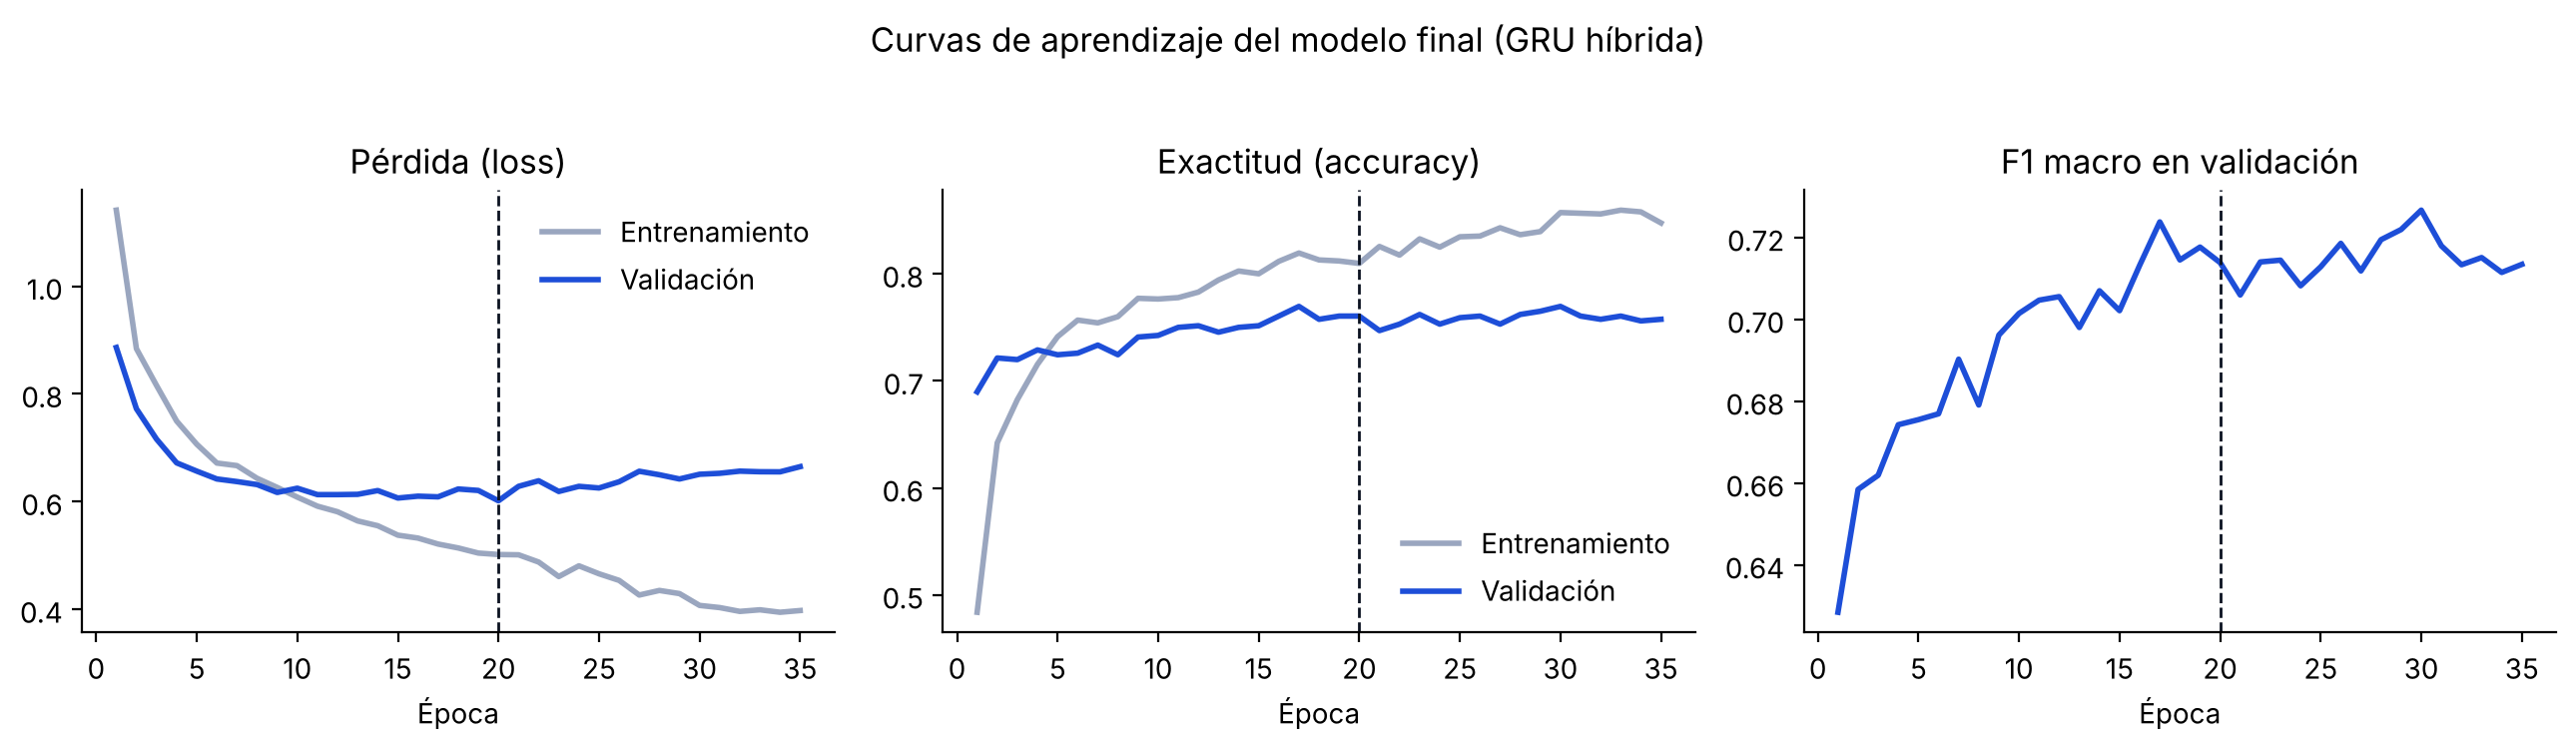

Mejor época: 20 de 35
  Pérdida    → entrenamiento 0.502 | validación 0.601
  Exactitud  → entrenamiento 0.810 | validación 0.761


In [12]:
os.makedirs("artefactos_paso3/figuras", exist_ok=True)

def curvas(h, titulo, archivo=None):
    ep = np.arange(1, len(h["loss"]) + 1); mejor = int(np.argmin(h["val_loss"])) + 1
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
    for ax, clave, nombre in [(axes[0], "loss", "Pérdida (loss)"), (axes[1], "accuracy", "Exactitud (accuracy)")]:
        ax.plot(ep, h[clave], color=GRIS, lw=2, label="Entrenamiento")
        ax.plot(ep, h["val_" + clave], color=AZUL, lw=2, label="Validación")
        ax.axvline(mejor, color=NEGRO, ls="--", lw=1); ax.set_title(nombre); ax.set_xlabel("Época")
        ax.legend(frameon=False)
    axes[2].plot(ep, h["val_f1_macro"], color=AZUL, lw=2); axes[2].axvline(mejor, color=NEGRO, ls="--", lw=1)
    axes[2].set_title("F1 macro en validación"); axes[2].set_xlabel("Época")
    for ax in axes: ax.spines[["top", "right"]].set_visible(False)
    fig.suptitle(titulo, y=1.03); plt.tight_layout()
    if archivo: fig.savefig(archivo, dpi=200, bbox_inches="tight")
    plt.show()
    return mejor

mejor_ep = curvas(hist_final, f"Curvas de aprendizaje del modelo final ({NOMBRE_FINAL})",
                  "artefactos_paso3/figuras/curvas_aprendizaje.png")
i = mejor_ep - 1
print(f"Mejor época: {mejor_ep} de {len(hist_final['loss'])}")
print(f"  Pérdida    → entrenamiento {hist_final['loss'][i]:.3f} | validación {hist_final['val_loss'][i]:.3f}")
print(f"  Exactitud  → entrenamiento {hist_final['accuracy'][i]:.3f} | validación {hist_final['val_accuracy'][i]:.3f}")

**Interpretación.** Las curvas muestran un entrenamiento sano hasta la época 20 y sobreajuste después:
- **Épocas 1 a 10:** las dos pérdidas bajan juntas. La red está aprendiendo patrones que también sirven para estudiantes que no ha visto.
- **Épocas 10 a 20:** la pérdida de entrenamiento sigue bajando, pero la de validación se estanca alrededor de 0,61. La red ya extrajo casi todo lo generalizable.
- **Después de la época 20:** la pérdida de validación sube poco a poco (hasta 0,67) mientras la de entrenamiento cae a 0,40, y la exactitud de entrenamiento llega a 0,85 con la de validación quieta en 0,76. Eso es **sobreajuste**: la red empieza a memorizar.

El *early stopping* detectó ese punto: detuvo el entrenamiento en la época 35 y **recuperó los pesos de la época 20**, donde la pérdida de validación fue mínima (0,601). En esa época la exactitud es 0,810 en entrenamiento y 0,761 en validación: una brecha de 5 puntos, moderada y esperable con pocos datos.

Dos aclaraciones para leer bien el gráfico:
- En las primeras épocas la pérdida de entrenamiento es **mayor** que la de validación. No es un error: durante el entrenamiento el *dropout* está activo y la pérdida incluye los pesos por clase y la penalización L2; en validación no.
- El F1 macro de validación oscila entre 0,70 y 0,73 de una época a otra. Esa oscilación es del mismo tamaño que las diferencias entre modelos vistas antes, lo que confirma por qué fue necesario comparar promedios de varias semillas.

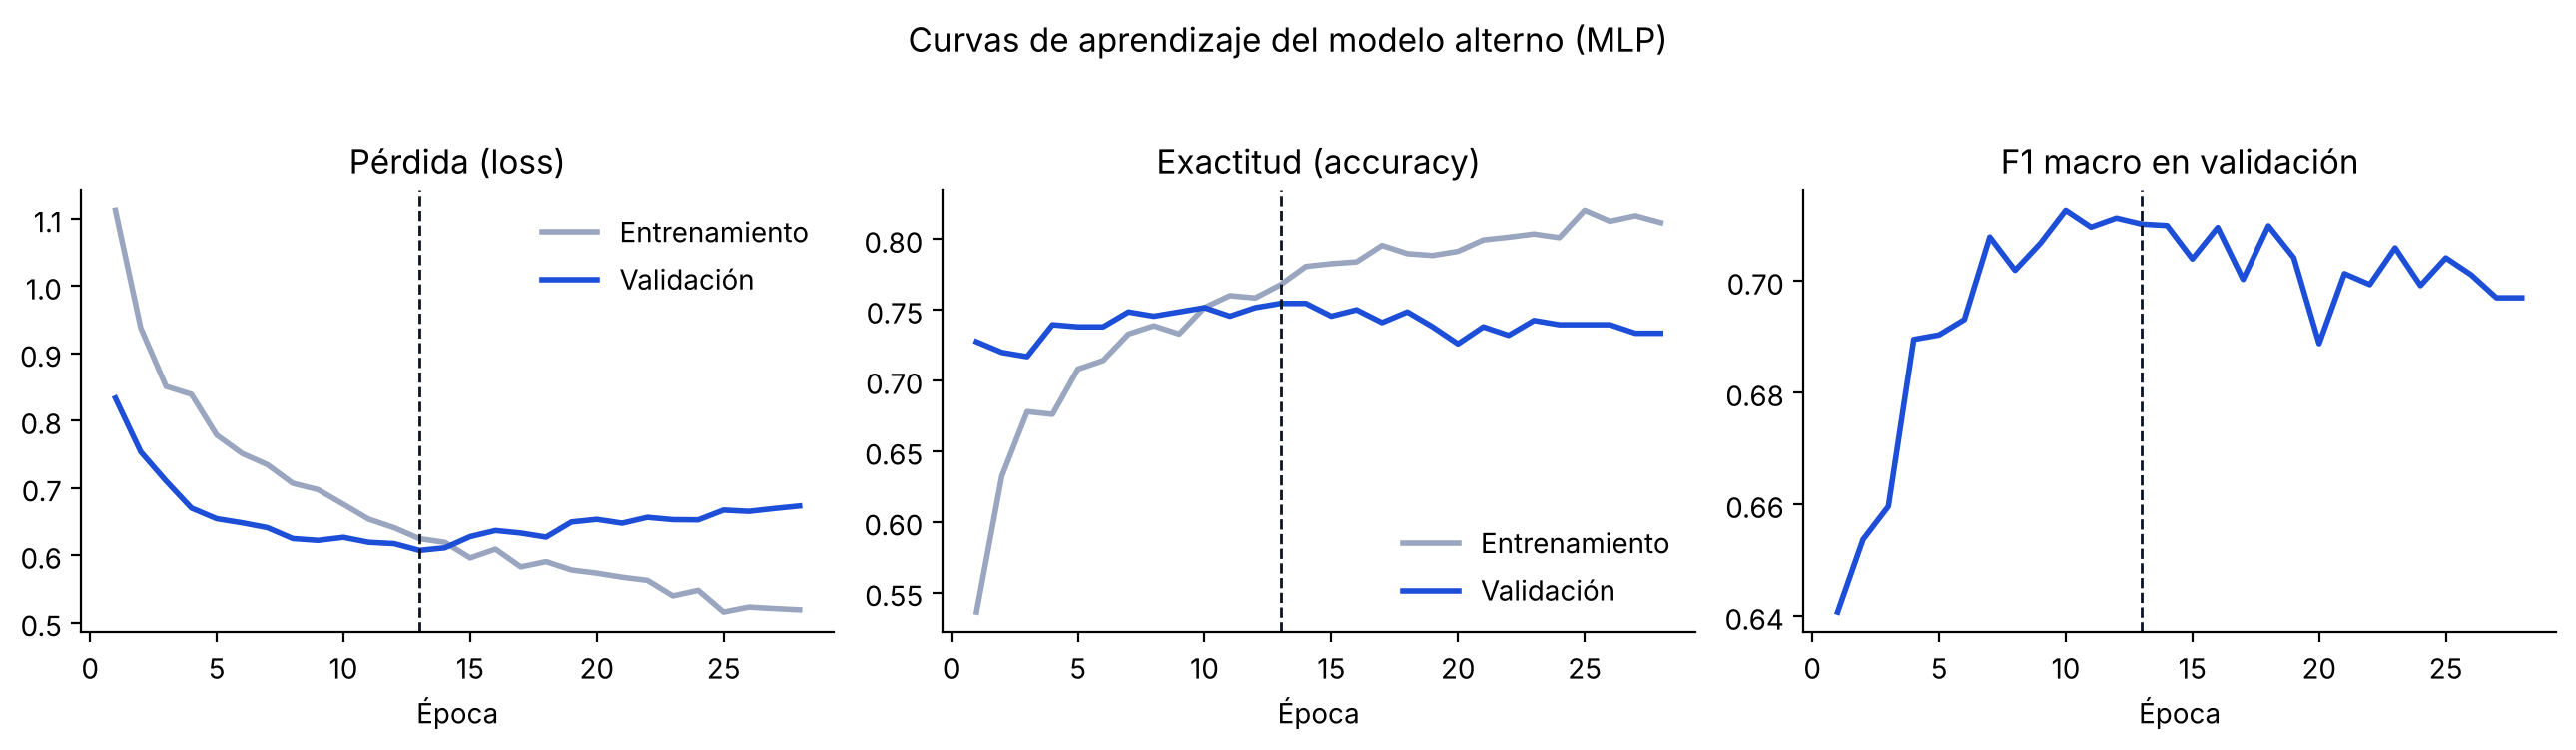

In [13]:
otro_h, otro_n = (hist_gru, "GRU híbrida") if GANA_MLP else (hist_mlp, "MLP")
_ = curvas(otro_h, f"Curvas de aprendizaje del modelo alterno ({otro_n})")

## 8. Evaluación final en el conjunto de prueba
Hasta aquí todas las decisiones se tomaron con validación. Ahora, **por única vez**, el modelo final se evalúa con los 664 estudiantes de prueba, que no participaron en nada.

In [14]:
proba_test = modelo_final.predict(entradas(Xte), verbose=0)
pred_test = proba_test.argmax(axis=1)
m_test = metricas(yte, proba_test)
m_test["f1_ponderado"] = f1_score(yte, pred_test, average="weighted")
m_test["auc_ovr_macro"] = roc_auc_score(yte, proba_test, multi_class="ovr", average="macro")

# Intervalo de confianza del 95 % por bootstrap: ¿cuánto podría variar el F1 con otros 664 estudiantes?
rng = np.random.default_rng(SEMILLA)
boot = []
for _ in range(2000):
    idx = rng.integers(0, len(yte), len(yte))
    boot.append(f1_score(yte[idx], pred_test[idx], average="macro"))
ic = np.percentile(boot, [2.5, 97.5])

print(f"Modelo final: {NOMBRE_FINAL}")
print(f"  Pérdida (loss)       {m_test['loss']:.3f}")
print(f"  Exactitud (accuracy) {m_test['accuracy']:.3f}")
print(f"  F1 macro             {m_test['f1_macro']:.3f}   (IC 95 %: {ic[0]:.3f} – {ic[1]:.3f})")
print(f"  F1 ponderado         {m_test['f1_ponderado']:.3f}")
print(f"  AUC macro (OvR)      {m_test['auc_ovr_macro']:.3f}\n")
print(classification_report(yte, pred_test, target_names=NOMBRES, digits=3))

Modelo final: GRU híbrida
  Pérdida (loss)       0.588
  Exactitud (accuracy) 0.752
  F1 macro             0.709   (IC 95 %: 0.672 – 0.743)
  F1 ponderado         0.760
  AUC macro (OvR)      0.895

                   precision    recall  f1-score   support

         Abandono      0.804     0.714     0.756       213
Sigue matriculado      0.453     0.613     0.521       119
        Se gradúa      0.873     0.825     0.848       332

         accuracy                          0.752       664
        macro avg      0.710     0.717     0.709       664
     weighted avg      0.776     0.752     0.760       664



**Interpretación.** En estudiantes que nunca vio, el modelo final obtiene:
- **F1 macro 0,709**, prácticamente igual al de validación (0,712 en promedio). Que no haya caída indica que el modelo **generaliza** y que no se sobreajustó a la validación al elegir configuraciones.
- **Exactitud 0,752:** acierta la clase de 3 de cada 4 estudiantes.
- **Pérdida 0,588** y **AUC 0,895:** las probabilidades ordenan bien a los estudiantes, incluso cuando la clase final asignada es incorrecta.

**Intervalo de confianza.** Con solo 664 estudiantes de prueba, el F1 macro real está entre **0,672 y 0,743** (IC 95 %). Es un margen de ± 3,5 puntos: cualquier diferencia más pequeña entre dos modelos no se puede afirmar con estos datos.

**Por clase:**
| Clase | Precisión | Recall | Lectura |
|---|---|---|---|
| Se gradúa | 0,873 | 0,825 | La clase mejor resuelta. |
| Abandono | 0,804 | 0,714 | Cuando el modelo dice «abandono» acierta 8 de cada 10 veces, pero deja pasar a casi 3 de cada 10 desertores. |
| Sigue matriculado | 0,453 | 0,613 | La clase débil: más de la mitad de las veces que el modelo la predice, se equivoca. |

### Matriz de confusión

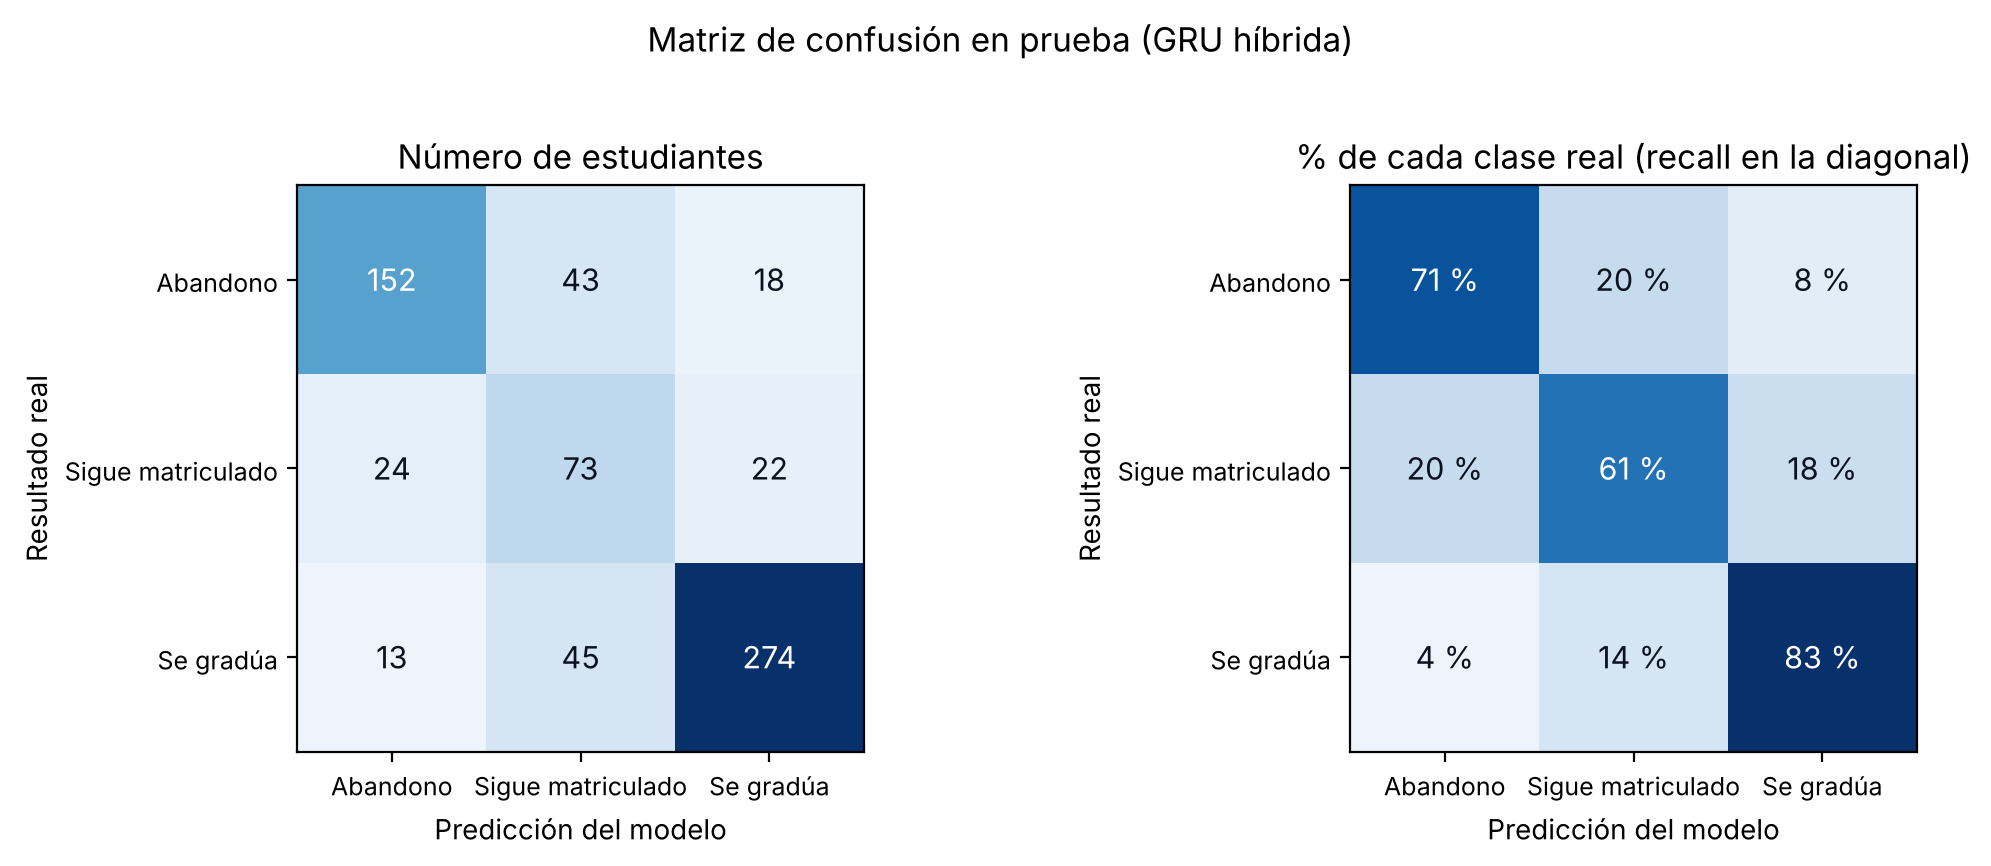

In [15]:
cm = confusion_matrix(yte, pred_test)
cm_pct = cm / cm.sum(axis=1, keepdims=True) * 100
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, datos, titulo, fmt in [(axes[0], cm, "Número de estudiantes", "{:.0f}"),
                               (axes[1], cm_pct, "% de cada clase real (recall en la diagonal)", "{:.0f} %")]:
    ax.imshow(datos, cmap="Blues", vmin=0)
    for r in range(3):
        for c in range(3):
            ax.text(c, r, fmt.format(datos[r, c]), ha="center", va="center", fontsize=11,
                    color="white" if datos[r, c] > datos.max() * 0.55 else NEGRO)
    ax.set_xticks(range(3), NOMBRES, fontsize=9); ax.set_yticks(range(3), NOMBRES, fontsize=9)
    ax.set_xlabel("Predicción del modelo"); ax.set_ylabel("Resultado real"); ax.set_title(titulo)
fig.suptitle(f"Matriz de confusión en prueba ({NOMBRE_FINAL})", y=1.02); plt.tight_layout()
fig.savefig("artefactos_paso3/figuras/matriz_confusion.png", dpi=200, bbox_inches="tight"); plt.show()

**Interpretación.** La matriz muestra **dónde** se equivoca el modelo:
- **Casi todos los errores pasan por «sigue matriculado».** De los 213 desertores reales, 43 (20 %) fueron clasificados como «sigue matriculado» y solo 18 (8 %) como «se gradúa». De los 332 graduados, 45 (14 %) cayeron en «sigue matriculado».
- **El error grave es poco frecuente.** Confundir un abandono con una graduación (o al revés) ocurre en 31 de 664 casos (4,7 %). El modelo casi nunca confunde los dos extremos.
- **«Sigue matriculado» se reparte a ambos lados:** de sus 119 estudiantes, 24 se predicen como abandono y 22 como graduación.

Tiene sentido: «sigue matriculado» no es un desenlace sino un estado **sin resolver**. Esos estudiantes terminarán graduándose o abandonando, y sus datos se parecen a los de uno u otro grupo. Además, los pesos por clase empujan al modelo a predecir esta categoría con más frecuencia (161 predicciones para 119 casos reales), lo que explica su baja precisión.

**Consecuencia práctica:** una predicción de «sigue matriculado» debe leerse como **zona de incertidumbre**, no como «sin riesgo»: el 27 % de esas predicciones (43 de 161) corresponde a estudiantes que en realidad abandonaron.

### Comparación en prueba con las referencias
Las referencias y el modelo neuronal alterno se evalúan en la misma prueba **solo para reportar**: el modelo final ya estaba elegido con validación.

In [16]:
otro_modelo, otra_ent = (gru, a_secuencia) if GANA_MLP else (mlp, lambda X: X)
comparacion = {
    f"{NOMBRE_FINAL} (modelo final)": m_test,
    f"{otro_n} (alterno)": metricas(yte, otro_modelo.predict(otra_ent(Xte), verbose=0)),
}
for nombre, m in referencias.items():
    comparacion[nombre] = metricas(yte, m.predict_proba(Xte))
tabla_comp = pd.DataFrame(comparacion).T[["f1_macro", "accuracy", "loss", "f1_abandono", "f1_matriculado", "f1_gradua"]].round(3)
tabla_comp

,f1_macro,accuracy,loss,f1_abandono,f1_matriculado,f1_gradua
GRU híbrida (modelo final),0.709,0.752,0.588,0.756,0.521,0.848
MLP (alterno),0.727,0.770,0.566,0.786,0.540,0.857
Regresión logística,0.696,0.729,0.617,0.756,0.515,0.817
Gradient Boosting (ACA 1),0.704,0.739,0.601,0.760,0.522,0.830


**Interpretación.** Tres lecturas, de la más a la menos cómoda:

1. **Las redes neuronales quedan al nivel del Gradient Boosting.** En prueba, la GRU obtiene 0,709 y el Gradient Boosting 0,704; la regresión logística, 0,696. Todos caben dentro del intervalo de confianza (0,672 – 0,743), así que **no se puede afirmar que un modelo sea mejor que otro**. Las redes igualan al mejor modelo clásico, no lo superan con claridad, lo cual es consistente con lo que se sabe sobre datos tabulares (Grinsztajn et al., 2022).
2. **El MLP alterno obtuvo más en prueba (0,727) que el modelo final (0,709).** Aun así, el modelo final **no se cambia**. Elegir el modelo mirando la prueba convertiría la prueba en un segundo conjunto de validación y el resultado reportado dejaría de ser honesto. La diferencia de 1,8 puntos está dentro del margen de error y, en validación, el orden fue el contrario.
3. **Un modelo lineal queda a solo 1,3 puntos.** La mayor parte de la señal del dataset es simple: aprobar o no las asignaturas y estar o no al día con la matrícula.

**Conclusión de la comparación:** el valor de la red neuronal en este proyecto no está en una mejora de exactitud sino en que alcanza el nivel del mejor modelo clásico con una arquitectura que puede crecer (más semestres en la secuencia, más datos), y en que entrega probabilidades bien ordenadas (AUC 0,895) útiles para priorizar.

## 9. Uso práctico: detectar abandono a tiempo
Para una oficina de permanencia estudiantil, la pregunta útil no es «¿cuál de las tres clases?» sino «**¿a quién llamo?**». Eso depende de la probabilidad de abandono que entrega la red y del **umbral** a partir del cual se activa la alerta:
- Umbral bajo → se detectan más desertores (más *recall*), pero se llama a más estudiantes que no iban a abandonar (menos *precisión*).
- Umbral alto → menos falsas alarmas, pero se escapan más desertores.

In [17]:
real_abandono = (yte == 0).astype(int)
p_abandono = proba_test[:, 0]
filas = []
for u in [0.2, 0.3, 0.4, 0.5, 0.6, 0.7]:
    alerta = (p_abandono >= u).astype(int)
    filas.append({"Umbral": u, "Estudiantes alertados": int(alerta.sum()),
                  "Desertores detectados (recall)": recall_score(real_abandono, alerta),
                  "Alertas correctas (precisión)": precision_score(real_abandono, alerta, zero_division=0)})
tabla_umbral = pd.DataFrame(filas).round(3)
print(f"Desertores reales en prueba: {int(real_abandono.sum())} de {len(yte)}")
tabla_umbral

Desertores reales en prueba: 213 de 664


,Umbral,Estudiantes alertados,Desertores detectados (recall),Alertas correctas (precisión)
0,0.2,268,0.850,0.675
1,0.3,227,0.803,0.753
2,0.4,206,0.765,0.791
3,0.5,180,0.709,0.839
4,0.6,165,0.667,0.861
5,0.7,145,0.610,0.897


**Interpretación.** La tabla muestra el intercambio entre detectar más desertores y generar menos falsas alarmas (213 desertores reales en prueba):
- **Umbral 0,5:** se alerta sobre 180 estudiantes, se detecta al 70,9 % de los desertores y el 83,9 % de las alertas es correcto.
- **Umbral 0,3:** se alerta sobre 227 estudiantes y se detecta al 80,3 %, con una precisión de 75,3 %. Se ganan 20 desertores detectados a cambio de 47 llamadas más, de las cuales 27 son falsas alarmas.
- **Umbral 0,2:** se detecta al 85,0 %, pero una de cada tres alertas es innecesaria.

No hay un umbral «correcto»: depende de cuánto cuesta cada error. Si la intervención es barata (un correo, una llamada de un tutor), conviene un umbral bajo como **0,3**, porque no detectar a un estudiante que va a abandonar cuesta más que hacer una llamada de sobra. Si la intervención es costosa (una beca), conviene un umbral alto.

**Para la app de Streamlit:** en lugar de mostrar solo la clase, se puede mostrar la probabilidad de abandono con un semáforo, por ejemplo: riesgo bajo (< 0,3), medio (0,3 – 0,5) y alto (≥ 0,5).

## 10. Guardar el modelo y las métricas
| Archivo | Contenido | Lo usa |
|---|---|---|
| `modelo_desercion.keras` | Red neuronal final (arquitectura + pesos) | App de Streamlit |
| `metricas_paso3_4.json` | Arquitectura, hiperparámetros, experimentos y métricas | Póster y app |
| `figuras/*.png` | Curvas de aprendizaje y matriz de confusión | Póster |

In [18]:
modelo_final.save("artefactos_paso3/modelo_desercion.keras")

def a_dict(tabla):
    return {k: {c: round(float(x), 4) for c, x in fila.items()} for k, fila in tabla.to_dict("index").items()}

resultado = {
    "modelo_final": NOMBRE_FINAL,
    "arquitectura": {"entradas": int(N_ENTRADAS), **({"capas_ocultas": list(PARAMS_MLP["capas"]),
                     "dropout": PARAMS_MLP["dropout"]} if GANA_MLP else {"gru": 32, "densas": [128, 64], "dropout": 0.3}),
                     "salida": "3 neuronas softmax", "parametros": int(modelo_final.count_params())},
    "entrenamiento": {"optimizador": "Adam", "tasa_aprendizaje": 0.001, "lote": 64, "l2": 1e-4,
                      "estrategia_desbalance": mejor1, "epocas": len(hist_final["loss"]), "mejor_epoca": int(mejor_ep),
                      "early_stopping": "val_loss, paciencia 15", "semilla": SEMILLA},
    "metricas_prueba": {k: round(float(v), 4) for k, v in m_test.items()},
    "ic95_f1_macro_prueba": [round(float(ic[0]), 4), round(float(ic[1]), 4)],
    "matriz_confusion_prueba": cm.tolist(),
    "clases": CLASES, "nombres_clases": NOMBRES,
    "experimento_desbalance_validacion": a_dict(res1),
    "experimento_arquitectura_validacion": a_dict(res2),
    "mlp_vs_gru_validacion": a_dict(res3),
    "comparacion_prueba": a_dict(tabla_comp),
    "umbrales_abandono_prueba": tabla_umbral.to_dict("records"),
    "versiones": {"keras": keras.__version__, "backend": keras.backend.backend(), "scikit-learn": sklearn.__version__,
                  "numpy": np.__version__},
}
with open("artefactos_paso3/metricas_paso3_4.json", "w", encoding="utf-8") as f:
    json.dump(resultado, f, ensure_ascii=False, indent=2)

for raiz, _, archivos in os.walk("artefactos_paso3"):
    for a in sorted(archivos):
        ruta = os.path.join(raiz, a)
        print(f"{ruta:<52} {os.path.getsize(ruta) / 1024:8.1f} KB")

artefactos_paso3/metricas_paso3_4.json                    5.4 KB
artefactos_paso3/modelo_desercion.keras                 395.5 KB
artefactos_paso3/figuras/curvas_aprendizaje.png         158.8 KB
artefactos_paso3/figuras/matriz_confusion.png           122.1 KB


### Prueba de extremo a extremo (lo que hará la app de Streamlit)
Se carga el modelo guardado y el preprocesador del Paso 2, y se predice para un estudiante tomado **en bruto** de la base de datos. Si el resultado coincide con el del notebook, la app podrá usar exactamente estos archivos.

In [19]:
import sys, sqlite3, joblib
sys.path.insert(0, CARPETA)                      # el preprocesador necesita importar preprocesamiento.py

modelo_cargado = keras.saving.load_model("artefactos_paso3/modelo_desercion.keras")
preprocesador = joblib.load(f"{CARPETA}/preprocesador.joblib")

conn = sqlite3.connect(f"{CARPETA}/desercion.db")
est = pd.read_sql("SELECT v.* FROM vista_modelo v JOIN particiones p USING (estudiante_id) "
                  "WHERE p.conjunto = 'prueba' ORDER BY v.estudiante_id LIMIT 1", conn)
conn.close()

x = preprocesador.transform(est[cfg["columnas_entrada"]]).astype("float32")
p = modelo_cargado.predict(entradas(x), verbose=0)[0]
print(f"Estudiante {int(est.estudiante_id[0])} · resultado real: {cfg['nombres_clases'][est.target[0]]}")
for nombre, prob in zip(NOMBRES, p):
    print(f"  {nombre:<18} {prob:6.1%}")

assert np.allclose(modelo_cargado.predict(entradas(Xte), verbose=0), proba_test, atol=1e-5)
print("✅ El modelo guardado reproduce exactamente las predicciones del notebook.")

Estudiante 3 · resultado real: Abandono
  Abandono            99.9%
  Sigue matriculado    0.1%
  Se gradúa            0.0%


✅ El modelo guardado reproduce exactamente las predicciones del notebook.


In [20]:
shutil.make_archive("artefactos_paso3", "zip", "artefactos_paso3")
try:
    from google.colab import files
    files.download("artefactos_paso3.zip")
except ImportError:
    print("Fuera de Colab: el archivo artefactos_paso3.zip quedó en la carpeta actual.")

Fuera de Colab: el archivo artefactos_paso3.zip quedó en la carpeta actual.


## 11. Conclusiones de los Pasos 3 y 4
1. **Arquitectura final:** red **híbrida GRU + densa**. Una GRU de 32 unidades lee los dos semestres como secuencia y una capa densa de 128 neuronas procesa las variables estáticas; ambas ramas se unen en una capa de 64 neuronas y una salida *softmax* de 3 clases (28.675 parámetros). Se entrenó con Adam, pesos por clase, *dropout*, regularización L2, *batch normalization* y *early stopping*.
2. **Selección rigurosa:** cada configuración se entrenó con 5 semillas y todas las decisiones (desbalance, tamaño de la red, MLP o GRU) se tomaron con validación. La prueba se usó una sola vez.
3. **Resultados en prueba:** F1 macro **0,709** (IC 95 %: 0,672 – 0,743), exactitud **0,752**, pérdida **0,588** y AUC **0,895**. No hay caída respecto a validación: el modelo generaliza.
4. **Curvas de aprendizaje:** aprendizaje sano hasta la época 20 y sobreajuste después, controlado por el *early stopping*.
5. **Dónde falla:** en la clase «sigue matriculado» (F1 0,521), que es un estado sin resolver más que un desenlace. Los errores graves (confundir abandono con graduación) son solo el 4,7 %.
6. **Hallazgos que conviene decir con claridad en la sustentación:**
   - El aumento de datos con SMOTE-NC **no mejoró** el resultado frente a los pesos por clase.
   - Hacer la red más grande **no mejoró** el resultado: el límite está en los datos, no en la arquitectura.
   - La red neuronal **iguala** al Gradient Boosting de la ACA 1 (0,709 frente a 0,704), pero no lo supera de forma demostrable.
   - MLP y GRU quedaron en empate técnico; la GRU aprendió por sí sola la tendencia entre semestres.
7. **Limitaciones:** un solo dataset de una institución portuguesa (los resultados no se trasladan directamente a Colombia), solo dos semestres de historia y un conjunto de prueba pequeño (664 estudiantes), que deja un margen de ± 3,5 puntos.

**Lo que recibe el Paso 5 (Streamlit):** `modelo_desercion.keras`, `preprocesador.joblib`, `preprocesamiento.py` y `config_preparacion.json`. La app debe aplicar el preprocesador, separar la entrada en secuencia y variables estáticas (función `a_secuencia`) y mostrar las tres probabilidades.

> **Nota de reproducibilidad.** Los textos de interpretación describen la ejecución guardada en este notebook (Keras 3 sobre JAX, semilla 42). Si se vuelve a ejecutar en otro entorno, los decimales pueden cambiar levemente y, al ser un empate técnico, el modelo elegido podría ser el MLP; en ese caso hay que revisar los textos.

### Referencias
- Chawla, N. V., Bowyer, K. W., Hall, L. O., & Kegelmeyer, W. P. (2002). SMOTE: Synthetic minority over-sampling technique. *Journal of Artificial Intelligence Research, 16*, 321–357. https://doi.org/10.1613/jair.953
- Cho, K., van Merriënboer, B., Gulcehre, C., Bahdanau, D., Bougares, F., Schwenk, H., & Bengio, Y. (2014). Learning phrase representations using RNN encoder–decoder for statistical machine translation. En *Proceedings of the 2014 Conference on Empirical Methods in Natural Language Processing* (pp. 1724–1734). https://doi.org/10.3115/v1/D14-1179
- Chollet, F., et al. (2015). *Keras* [Software]. https://keras.io
- Grinsztajn, L., Oyallon, E., & Varoquaux, G. (2022). Why do tree-based models still outperform deep learning on typical tabular data? *Advances in Neural Information Processing Systems, 35*, 507–520.
- Ioffe, S., & Szegedy, C. (2015). Batch normalization: Accelerating deep network training by reducing internal covariate shift. En *Proceedings of the 32nd International Conference on Machine Learning* (pp. 448–456).
- Kingma, D. P., & Ba, J. (2015). Adam: A method for stochastic optimization. En *3rd International Conference on Learning Representations*. https://arxiv.org/abs/1412.6980
- Martins, M. V., Real, M. B., Machado, J., & Becker, A. (2021). *UCI Predict Students Dropout and Academic Success* [Conjunto de datos]. UCI Machine Learning Repository. https://archive.ics.uci.edu/dataset/697/predict+students+dropout+and+academic+success
- Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., … Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830.
- Srivastava, N., Hinton, G., Krizhevsky, A., Sutskever, I., & Salakhutdinov, R. (2014). Dropout: A simple way to prevent neural networks from overfitting. *Journal of Machine Learning Research, 15*(56), 1929–1958.